# Random Forest V3

For V3, I changed the maximum depth to see how it would affect the Random Forest. I kept the tree counts selected in V2 and compared depths 2, 3, 5 and 8 on the same samples.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))
from src.data_loader import load_task, split_train_val
from src.models.random_forest import RandomForest

result_dir = project_root / "results/random_forest"
data_dir = project_root.parent / "data"
depths = [2, 3, 5, 8]
v2_summary = pd.read_csv(result_dir / "random_forest_v2_summary.csv", float_precision="round_trip")
summary_rows = []
selected = {}
print(f"Python {platform.python_version()}, NumPy {np.__version__}, pandas {pd.__version__}")


Python 3.14.3, NumPy 2.4.3, pandas 3.0.1


I started by testing the different depths on the image dataset.

In [2]:
task = "image"
v2_best = v2_summary.loc[v2_summary.dataset == task].sort_values(
    ["validation_accuracy", "n_trees"], ascending=[False, True]).iloc[0]
n_trees = int(v2_best.n_trees)
assert n_trees == 20
X, y, _, _ = load_task(task, data_dir=data_dir)
X_train_full, X_val_full, y_train_full, y_val_full = split_train_val(X, y, val_fraction=0.2, seed=42)
X_train, y_train = X_train_full[:200], y_train_full[:200]
X_val, y_val = X_val_full[:200], y_val_full[:200]
assert X_train.shape == X_val.shape == (200, 500)
v2_validation = pd.read_csv(result_dir / f"random_forest_v2_{task}_validation.csv")
assert v2_validation.validation_index.tolist() == list(range(200))
assert v2_validation.actual_label.tolist() == y_val.tolist()
image_rows = []
image_predictions = {}
image_actual = y_val.copy()
for depth in depths:
    clf = RandomForest(n_trees=n_trees, max_depth=depth, min_samples=1, n_features="sqrt", seed=42)
    start = perf_counter()
    assert clf.fit(X_train, y_train) is clf
    fit_time = perf_counter() - start
    training_accuracy = clf.score(X_train, y_train)
    start = perf_counter()
    predictions = clf.predict(X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(predictions, y_val)) / 200
    oob_accuracy = clf.oob_score(y_train)
    assert len(clf.trees) == 20 and len(predictions) == 200
    assert all(t.criterion == "entropy" for t in clf.trees)
    assert all(0 <= p <= 49 for p in predictions)
    if depth == int(v2_best.max_depth):
        assert predictions == v2_validation.predicted_label.tolist()
        assert training_accuracy == v2_best.training_accuracy
        assert validation_accuracy == v2_best.validation_accuracy
        assert oob_accuracy == v2_best.oob_accuracy
        print(f"Depth {depth} reproduces all selected V2 predictions and train/validation/OOB scores exactly.")
    image_predictions[depth] = predictions
    row = {"dataset": task, "version": "V3", "n_trees": n_trees,
           "max_depth": depth, "min_samples": 1, "n_features": "sqrt",
           "criterion": "entropy", "normalized": False, "training_samples": 200,
           "validation_samples": 200, "training_accuracy": training_accuracy,
           "validation_accuracy": validation_accuracy, "oob_accuracy": oob_accuracy,
           "fit_time_seconds": fit_time, "prediction_time_seconds": prediction_time}
    image_rows.append(row)
    print(f"{task} depth={depth}: training={training_accuracy:.2%}, validation={validation_accuracy:.2%}, OOB={oob_accuracy:.2%} on {sum(bool(v) for v in clf._oob_preds.values())}/200")
    print(f"Fit={fit_time:.9f} s, predict={prediction_time:.9f} s")
summary_rows.extend(image_rows)


Depth 2 reproduces all selected V2 predictions and train/validation/OOB scores exactly.
image depth=2: training=11.50%, validation=3.50%, OOB=1.00% on 200/200
Fit=0.489268750 s, predict=0.001153542 s
image depth=3: training=23.00%, validation=3.50%, OOB=2.50% on 200/200
Fit=0.602583875 s, predict=0.001510708 s
image depth=5: training=71.50%, validation=3.50%, OOB=3.00% on 200/200
Fit=0.765617250 s, predict=0.002161333 s
image depth=8: training=99.00%, validation=7.50%, OOB=4.00% on 200/200
Fit=0.882448125 s, predict=0.002990208 s


Then I repeated the same experiment with the sentiment dataset.

In [3]:
task = "sentiment"
v2_best = v2_summary.loc[v2_summary.dataset == task].sort_values(
    ["validation_accuracy", "n_trees"], ascending=[False, True]).iloc[0]
n_trees = int(v2_best.n_trees)
assert n_trees == 20
X, y, _, _ = load_task(task, data_dir=data_dir)
X_train_full, X_val_full, y_train_full, y_val_full = split_train_val(X, y, val_fraction=0.2, seed=42)
X_train, y_train = X_train_full[:200], y_train_full[:200]
X_val, y_val = X_val_full[:200], y_val_full[:200]
assert X_train.shape == X_val.shape == (200, 768)
v2_validation = pd.read_csv(result_dir / f"random_forest_v2_{task}_validation.csv")
assert v2_validation.validation_index.tolist() == list(range(200))
assert v2_validation.actual_label.tolist() == y_val.tolist()
sentiment_rows = []
sentiment_predictions = {}
sentiment_actual = y_val.copy()
for depth in depths:
    clf = RandomForest(n_trees=n_trees, max_depth=depth, min_samples=1, n_features="sqrt", seed=42)
    start = perf_counter()
    assert clf.fit(X_train, y_train) is clf
    fit_time = perf_counter() - start
    training_accuracy = clf.score(X_train, y_train)
    start = perf_counter()
    predictions = clf.predict(X_val)
    prediction_time = perf_counter() - start
    validation_accuracy = sum(p == t for p, t in zip(predictions, y_val)) / 200
    oob_accuracy = clf.oob_score(y_train)
    assert len(clf.trees) == 20 and len(predictions) == 200
    assert all(t.criterion == "entropy" for t in clf.trees)
    assert all(0 <= p <= 2 for p in predictions)
    if depth == int(v2_best.max_depth):
        assert predictions == v2_validation.predicted_label.tolist()
        assert training_accuracy == v2_best.training_accuracy
        assert validation_accuracy == v2_best.validation_accuracy
        assert oob_accuracy == v2_best.oob_accuracy
        print(f"Depth {depth} reproduces all selected V2 predictions and train/validation/OOB scores exactly.")
    sentiment_predictions[depth] = predictions
    row = {"dataset": task, "version": "V3", "n_trees": n_trees,
           "max_depth": depth, "min_samples": 1, "n_features": "sqrt",
           "criterion": "entropy", "normalized": False, "training_samples": 200,
           "validation_samples": 200, "training_accuracy": training_accuracy,
           "validation_accuracy": validation_accuracy, "oob_accuracy": oob_accuracy,
           "fit_time_seconds": fit_time, "prediction_time_seconds": prediction_time}
    sentiment_rows.append(row)
    print(f"{task} depth={depth}: training={training_accuracy:.2%}, validation={validation_accuracy:.2%}, OOB={oob_accuracy:.2%} on {sum(bool(v) for v in clf._oob_preds.values())}/200")
    print(f"Fit={fit_time:.9f} s, predict={prediction_time:.9f} s")
summary_rows.extend(sentiment_rows)


sentiment depth=2: training=74.00%, validation=41.50%, OOB=46.50% on 200/200
Fit=2.866745625 s, predict=0.001165416 s
Depth 3 reproduces all selected V2 predictions and train/validation/OOB scores exactly.
sentiment depth=3: training=80.50%, validation=41.00%, OOB=46.50% on 200/200
Fit=3.659625500 s, predict=0.001571875 s
sentiment depth=5: training=99.50%, validation=43.00%, OOB=48.50% on 200/200
Fit=4.410720083 s, predict=0.002081375 s
sentiment depth=8: training=100.00%, validation=43.50%, OOB=45.50% on 200/200
Fit=4.639119708 s, predict=0.002418000 s


I plotted training and validation accuracy to compare the depths.

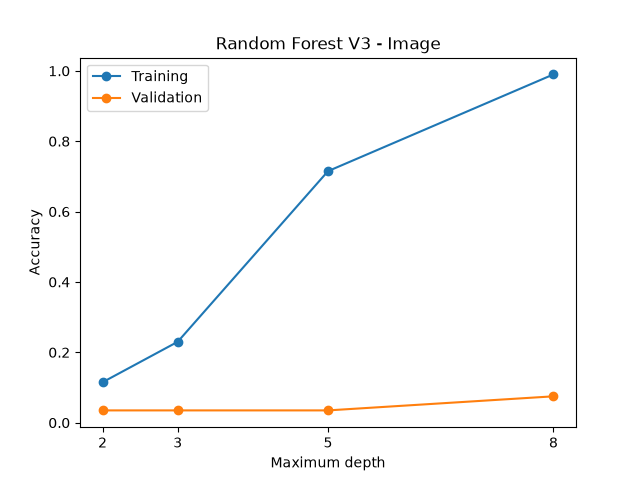

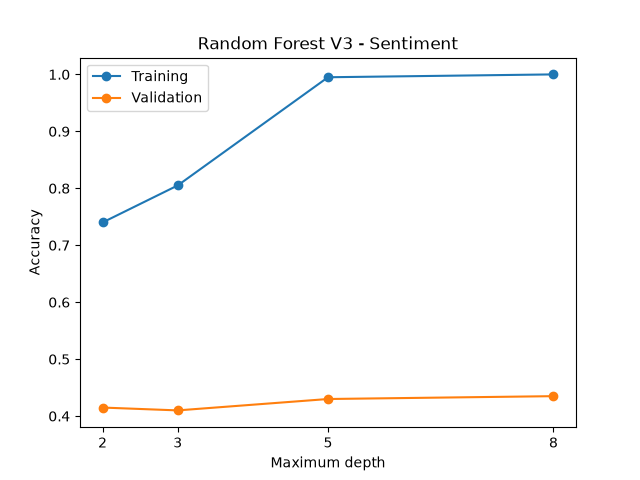

In [4]:
for task, rows in [("image", image_rows), ("sentiment", sentiment_rows)]:
    frame = pd.DataFrame(rows)
    plt.figure()
    plt.plot(frame.max_depth, frame.training_accuracy, marker="o", label="Training")
    plt.plot(frame.max_depth, frame.validation_accuracy, marker="o", label="Validation")
    plt.xlabel("Maximum depth")
    plt.ylabel("Accuracy")
    plt.title(f"Random Forest V3 - {task.capitalize()}")
    plt.xticks(depths)
    plt.legend()
    plt.savefig(result_dir / f"random_forest_v3_{task}_depth.png")
    plt.show()


Finally, I selected the best depth for each dataset using validation accuracy and saved its predictions. If accuracies tie, I keep the shallower depth.

In [5]:
summary = pd.DataFrame(summary_rows)
assert len(summary) == 8
summary.to_csv(result_dir / "random_forest_v3_summary.csv", index=False)
for task, rows, actual, prediction_map in [
    ("image", image_rows, image_actual, image_predictions),
    ("sentiment", sentiment_rows, sentiment_actual, sentiment_predictions),
]:
    best = rows[0]
    for row in rows[1:]:
        if row["validation_accuracy"] > best["validation_accuracy"]:
            best = row
    selected[task] = best
    path = result_dir / f"random_forest_v3_{task}_validation.csv"
    pd.DataFrame({"validation_index": range(200), "actual_label": actual,
                  "predicted_label": prediction_map[best["max_depth"]]}).to_csv(path, index=False)
    saved = pd.read_csv(path)
    assert saved.shape == (200, 3) and not saved.isna().any().any()
    assert saved.validation_index.tolist() == list(range(200))
    assert saved.actual_label.tolist() == actual.tolist()
    assert saved.predicted_label.tolist() == prediction_map[best["max_depth"]]
    assert sum(saved.actual_label == saved.predicted_label)/200 == best["validation_accuracy"]
    print(f"{task}: selected depth={best['max_depth']}, validation={best['validation_accuracy']:.2%}")
print(summary.to_string(index=False))
tracker_path = result_dir / "kaggle_scores.csv"
tracker = pd.read_csv(tracker_path, dtype=str, keep_default_na=False)
assert tracker.version.is_unique
previous_rows = tracker.loc[tracker.version != "V3"].to_dict("records")
v3_row = {"version": "V3", "image_validation_accuracy": selected["image"]["validation_accuracy"],
    "sentiment_validation_accuracy": selected["sentiment"]["validation_accuracy"],
    "kaggle_public_score": "", "submitted_to_kaggle": False, "submission_filename": "",
    "notes": f"Tested depths 2,3,5,8; selected image={selected['image']['max_depth']}, sentiment={selected['sentiment']['max_depth']}; 20 trees each; sqrt; min_samples=1; entropy; seed=42; original features; 200 train/200 validation per task. No Kaggle candidate."}
matching = tracker.version == "V3"
if matching.any():
    for col in ("image_validation_accuracy", "sentiment_validation_accuracy", "notes"):
        tracker.loc[matching, col] = str(v3_row[col])
else:
    tracker = pd.concat([tracker, pd.DataFrame([v3_row])], ignore_index=True)
assert tracker.version.is_unique
assert tracker.loc[tracker.version != "V3"].to_dict("records") == previous_rows
tracker.to_csv(tracker_path, index=False)


image: selected depth=8, validation=7.50%
sentiment: selected depth=8, validation=43.50%
  dataset version  n_trees  max_depth  min_samples n_features criterion  normalized  training_samples  validation_samples  training_accuracy  validation_accuracy  oob_accuracy  fit_time_seconds  prediction_time_seconds
    image      V3       20          2            1       sqrt   entropy       False               200                 200              0.115                0.035         0.010          0.489269                 0.001154
    image      V3       20          3            1       sqrt   entropy       False               200                 200              0.230                0.035         0.025          0.602584                 0.001511
    image      V3       20          5            1       sqrt   entropy       False               200                 200              0.715                0.035         0.030          0.765617                 0.002161
    image      V3       20         

I selected depth 8 for image (7.50% validation accuracy) and depth 8 for sentiment (43.50%). The matching baseline depths reproduced V2 exactly. These results use 200 validation examples per dataset.